In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import time # para obter seed a cada run no método init_run, comentdo para uso de seed fixa igual a 42
from abc import  ABC,abstractmethod

In [2]:
class StationaryKBanditEnv(gym.Env):
    # Entradas:
    # k - número de bandidos,
    # media_q_true - vetor de médias utilizado pela  normal que gera
    # recompensas para cada passo para cada bandido (*)
    # (*) - o bandido que é sorteado com maior media_q_true
    # é considerado escolha ótima para efeito de avaliação dos agentes
    # seed - semente do gerador aleatório
    def __init__(self, k=10, media_q_true = 0, seed=42):
        super().__init__()
        self.k = k
        self.action_space = spaces.Discrete(k)
        self.observation_space = spaces.Discrete(1)
        self.seed = seed
        self.media_q_true = media_q_true # Store media_q_true as an instance variable

        # Initialize true mean action values with mean
        # media_q_true and variance 1
        self.q_true = np.random.normal(self.media_q_true, 1, k)

    # Entradas:
    # action - ação no domínio de self.action_space
    # Saídas:
    # <obs, reward, terminated, trucated, dict info> - padrão de gym.Env
    # reward - recompensa gerada pela ação
    def step(self, action):
        reward = np.random.normal(self.q_true[action], 1)

        return 0, reward, False, False, {"q_true": self.q_true}  # Include q_true in info

    # Entrada:
    # seed - semente
    # Saídas:
    # <obs, dict_info> - padrão de gym.Env
    def reset(self, seed=42):
        super().reset(seed=seed)
        # Reinitialize true mean action values with self.media_q_true and variance 1
        self.q_true = np.random.normal(self.media_q_true, 1, self.k)
        return 0, {}

In [3]:
class NonStationaryKBanditEnv(StationaryKBanditEnv):
  # Entradas:
  # k - número de bandidos,
  # media_q_true - vetor de médias utilizado pela  normal que gera
  # recompensas para cada passo para cada bandido (*)
  # (*) - o bandido que é sorteado com maior media_q_true
  # é considerado escolha ótima para efeito de avaliação dos agentes
  # seed - semente do gerador aleatório
  # sigma_non_stationary - controla o efeito da não estacionariedade
  def __init__(self, k=10, media_q_true=0, seed=42, sigma_non_stationary=0.01):
    super().__init__(k=k, media_q_true=media_q_true, seed=seed)
    self.sigma_non_stationary = sigma_non_stationary

  # Entradas:
  # action - ação no domínio de self.action_space
  # Saídas:
  # <obs, reward, terminated, trucated, dict info> - padrão de gym.Env
  # reward - recompensa gerada pela ação
  def step(self, action):
        # Non-stationary: random walk with std=self.sigma_non_stationary
        self.q_true += np.random.normal(0, self.sigma_non_stationary, self.k)
        reward = np.random.normal(self.q_true[action], 1)

        # return <obs, reward, terminated, trucated, dict info
        return 0, reward, False, False, {"q_true": self.q_true}  # Include q_true in info

In [4]:
# Classe de Agentes Base Abstrata
# Soluções através dec classes derivadas para: ['alpha', 'ucb', 'Optimal_init', 'gradient']
class AgentKBandit(ABC):
  #Entrada:
  # env - ambiente
  def __init__(self, env):
    self.env = env

  def init_run (self, num_steps):
    # self.seed = int(time.time())
    self.seed = 42
    # Initialize Q-values and action counts
    self.Q = np.zeros(self.env.k)
    self.N = np.zeros(self.env.k)
    self.true_q_values = self.env.q_true
    self.optimal_action = np.argmax(self.true_q_values)
    self.run_rewards = np.zeros(num_steps)
    self.run_optimal = np.zeros(num_steps)
    self.run_regrets = np.zeros(num_steps)

  def store_results(self, step, action, reward):
    self.run_rewards[step] = reward
    self.run_optimal[step] = (action == self.optimal_action)
    self.run_regrets[step] = self.calcular_regret(action)

  def calcular_regret(self, acao):
    return max(self.env.q_true) - self.env.q_true[acao]

  @abstractmethod
  def get_label(self):
    pass

  @abstractmethod
  def run(self, num_steps):
    pass


In [5]:
class AgentAlpha(AgentKBandit):

  def __init__(self, env, alpha=0.1, epsilon = 0.1):
    super().__init__(env)
    self.alpha = alpha
    self.epsilon = epsilon

  def get_label(self):
    return f"α = {self.alpha} ε = {self.epsilon}"

  def run(self, num_steps = 1000):
    super().init_run(num_steps)

    for step in range(num_steps):
        # ε-greedy action selection
        if np.random.random() < self.epsilon:
            action = self.env.action_space.sample()
        else:
            # Escolha determinística em caso de empate
            # pega o menor índice entre os empatados
            #action = np.argmax(self.Q)
            # Encontra ações com Q máximo
            max_q = np.max(self.Q)
            best_actions = np.where(self.Q == max_q)[0]
            # Escolha aleatória entre ações ótimas (empates)
            action = np.random.choice(best_actions)  # ← esta é a diferença!

        # Take action and observe reward
        _, reward, _, _, _ = self.env.step(action)

        # Update Q-value
        if self.alpha == 0 or self.alpha == 0.0:  # Sample-average method
            self.N[action] += 1
            self.Q[action] += (reward - self.Q[action]) / self.N[action]
        else:  # Constant step-size
            self.Q[action] += self.alpha * (reward - self.Q[action])

        # Store results
        self.store_results(step, action, reward)

    return self.run_rewards, self.run_optimal, self.run_regrets

In [6]:
class AgentOptimalInit(AgentAlpha):
    def __init__(self, env, alpha=0.1, epsilon=0.1, initial_value=5):
        super().__init__(env, alpha, epsilon)
        self.initial_value = initial_value


    def init_run(self, num_steps):
        # self.seed = int(time.time())
        self.seed = 42
        # Initialize Q-values and action counts
        self.Q = np.full(self.env.k, self.initial_value)
        self.N = np.zeros(self.env.k)
        self.true_q_values = self.env.q_true
        self.optimal_action = np.argmax(self.true_q_values)
        self.run_rewards = np.zeros(num_steps)
        self.run_optimal = np.zeros(num_steps)
        self.run_regrets = np.zeros(num_steps)


    def get_label(self):
        return super().get_label() + f" init = {self.initial_value}"

    def run(self, num_steps=1000):
        self.init_run(num_steps)

        for step in range(num_steps):
            if np.random.random() < self.epsilon:
                action = self.env.action_space.sample()
            else:
                max_q = np.max(self.Q)
                best_actions = np.where(self.Q == max_q)[0]
                action = np.random.choice(best_actions)

            _, reward, _, _, _ = self.env.step(action)

            if self.alpha == 0 or self.alpha == 0.0:
                self.N[action] += 1
                self.Q[action] += (reward - self.Q[action]) / self.N[action]
            else:
                self.Q[action] += self.alpha * (reward - self.Q[action])

            self.store_results(step, action, reward)

        # ← ADICIONE ESTE RETURN:
        return self.run_rewards, self.run_optimal, self.run_regrets

In [7]:
class AgentUCB(AgentKBandit):

  def __init__(self, env, c =0.0):
    super().__init__(env)
    self.c = c

  def get_label(self):
    return f"UCB c = {self.c}"

  def run(self, num_steps = 1000):
    super().init_run(num_steps)

    for step in range(num_steps):

        if step < self.env.k: # Aciona cada um dos K bandidos inicialmente
            action = step
            # Take action and observe reward
            _, reward, _, _, _ = self.env.step(action)
            self.N[action] = 1
            self.Q[action] = reward
        else:
            # 1e-8 - proteção para self.N = 0, o que não ocorre
            action = np.argmax(self.Q + self.c * np.sqrt(np.log(step) / (self.N + 1e-8)))
            # Take action and observe reward
            _, reward, _, _, _ = self.env.step(action)
            self.N[action] += 1
            self.Q[action] += (reward - self.Q[action]) / self.N[action]

        # Store results
        self.store_results(step, action, reward)

    return self.run_rewards, self.run_optimal, self.run_regrets

In [ ]:
class AgentGradient(AgentKBandit):
  def __init__(self, env, alpha_lr = 0.1, baseline=True):
    super().__init__(env)
    self.alpha_lr = alpha_lr
    self.baseline = baseline # Corrected: Assign baseline parameter

  def init_run (self, numsteps):
    # self.seed = int(time.time())
    self.seed = 42
    # Initialize H-preferences
    self.H = np.zeros(self.env.k)
    self.R_avg = 0
    self.pi = np.ones(self.env.k)/self.env.k  # Initial policy (uniform)

    self.true_q_values = self.env.q_true
    self.optimal_action = np.argmax(self.true_q_values)
    self.run_rewards = np.zeros(numsteps)
    self.run_optimal = np.zeros(numsteps)
    self.run_regrets = np.zeros(numsteps)

  def get_label(self):
    YN = "" if self.baseline else "No"
    return f"Gradient - lr = {self.alpha_lr}"+ f" - {YN} Baseline "

  def run(self, num_steps):
    self.init_run(num_steps)
    # run_rewards = np.zeros(num_steps)
    # optimal_run_actions = np.zeros(num_steps)

    for step in range(num_steps):
      # Select action according to current policy
      action = np.random.choice(self.env.k, p=self.pi)

      # Take action and observe reward
      _, reward, _, _, _ = self.env.step(action)

      # Store results
      # run_rewards[step] += reward
      # optimal_run_actions[step] += (action == self.optimal_action)
      self.store_results(step, action, reward)

      # Gradient Bandit updates
      if self.baseline:
        self.R_avg = self.R_avg + (reward - self.R_avg)/(step + 1)  # Update average reward
        baseline_val = self.R_avg
      else:
        baseline_val = 0

      # Update all preferences using the correct gradient bandit update rule
      self.H -= self.alpha_lr * (reward - baseline_val) * self.pi
      self.H[action] += self.alpha_lr * (reward - baseline_val)

      # Update policy using softmax
      # Subtract max for numerical stability, then update self.pi
      exp_h = np.exp(self.H - np.max(self.H))
      self.pi = exp_h / exp_h.sum()

    return self.run_rewards, self.run_optimal, self.run_regrets

In [ ]:
class AgentTS(AgentKBandit):
    # mu_0 e sigma_0 - valores iniciais de média e desvio padrão
    # usados para estimativa das distribuições normais de recompensas das alavancas dos k bandidos
    def __init__(self, env, mu_0=0.0, sigma_0=1.0):
        super().__init__(env)
        self.mu_0 = mu_0
        self.sigma_0 = sigma_0
        self.sigma2_0 = sigma_0 * sigma_0

        self.mu = None
        self.sigma2 = None          # variância da crença (incerteza sobre μ)
        self.sigma2_estimada = None # variância estimada dos dados
        self.n = None               # nr de acionamentos da alavanca escolhida
        self.rewards_history = None # histórico de recompensas da alavanca escolhida

    def get_label(self):
        return f'Thompson Sampling (σ₀={self.sigma_0})'

    def init_run(self, num_steps):
        super().init_run(num_steps)
        self.mu = np.full(self.env.k, self.mu_0)
        self.sigma2 = np.full(self.env.k, self.sigma2_0)
        self.sigma2_estimada = np.full(self.env.k, self.sigma2_0)
        self.n = np.zeros(self.env.k)
        self.rewards_history = [[] for _ in range(self.env.k)]

    def run(self, num_steps):
        self.init_run(num_steps)

        for step in range(num_steps):
            # Amostrar da posterior
            samples = np.random.normal(self.mu, np.sqrt(self.sigma2))
            action = np.argmax(samples)

            # Sorteia recompensa pelo modelo do ambiente
            _, reward, _, _, _ = self.env.step(action)

            # Atualizar histórico
            self.rewards_history[action].append(reward)
            self.n[action] += 1
            n = self.n[action]

            # Estimar variância REAL a partir dos dados (se houver dados suficientes)
            if n >= 3:
                # ddof=1: variância amostral (divide por n-1) para estimador não viesado
                self.sigma2_estimada[action] = np.var(self.rewards_history[action], ddof=1)
            # Se n < 3, mantém o valor anterior (prior)

            # Atualizar média e variância da crença
            self.mu[action] = np.mean(self.rewards_history[action])
            self.sigma2[action] = self.sigma2_estimada[action] / n

            # Compatibilidade com a classe base
            self.N[action] += 1
            self.Q[action] = self.mu[action]

            self.store_results(step, action, reward)

        return self.run_rewards, self.run_optimal, self.run_regrets

In [8]:
class EvaluateKBanditAgents():

  def __init__(self, agents, env, num_runs = 100, num_steps = 1000, verbose = True):
    self.agents = agents
    self.env = env
    self.num_runs = num_runs
    self.num_steps = num_steps
    self.verbose = verbose


  def _plot_results_paper(self, avg_rewards, optimal_actions, avg_regrets, cumulative_regrets):
    """Plota 2 figures separadas para o artigo"""

    colors = plt.cm.jet(np.linspace(0, 1, len(self.agents)))
    labels = [agent.get_label() for agent in self.agents]
    steps = np.arange(self.num_steps)

    # FIGURE 1:
    fig1, axes1 = plt.subplots(1, 2, figsize=(12, 5))

    # Average Reward
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes1[0].plot(steps, avg_rewards[i], color=color, label=label)
    axes1[0].set_xlabel('Steps')
    axes1[0].set_ylabel('Average Reward')
    axes1[0].set_title('Average Reward vs Steps')
    axes1[0].legend()
    axes1[0].grid(True)

    # % Optimal Action
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes1[1].plot(steps, 100.0 * optimal_actions[i], color=color, label=label)
    axes1[1].set_xlabel('Steps')
    axes1[1].set_ylabel('% Optimal Action')
    axes1[1].set_title('Optimal Action Selection vs Steps')
    axes1[1].legend()
    axes1[1].grid(True)

    plt.tight_layout()
    plt.savefig('figure1_barsi_replica.pdf', dpi=300)
    plt.show()

    # FIGURE 2: Análise de Regret (sua contribuição)
    fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))

    # Average Regret
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes2[0].plot(steps, avg_regrets[i], color=color, label=label)
    axes2[0].set_xlabel('Steps')
    axes2[0].set_ylabel('Average Regret')
    axes2[0].set_title('Average Regret vs Steps')
    axes2[0].legend()
    axes2[0].grid(True)

    # Cumulative Regret
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes2[1].plot(steps, cumulative_regrets[i], color=color, label=label)
    axes2[1].set_xlabel('Steps')
    axes2[1].set_ylabel('Cumulative Regret')
    axes2[1].set_title('Cumulative Regret vs Steps')
    axes2[1].legend()
    axes2[1].grid(True)

    plt.tight_layout()
    plt.savefig('figure2_regret_analysis.pdf', dpi=300)
    plt.show()

  def run(self):
    num_agents = len(self.agents)
    avg_rewards = np.zeros((num_agents, self.num_steps))
    optimal_actions = np.zeros((num_agents, self.num_steps))
    avg_regrets = np.zeros((num_agents, self.num_steps))
    cumulative_regrets = np.zeros((num_agents, self.num_steps))


    for run in range(self.num_runs):
      if self.verbose:
        print(f"Run {run+1}/{self.num_runs}")

      # Reset environment ONCE per run, before any agent runs
      # This ensures all agents in this 'run' face the same bandit problem instance
      # self.env.reset()

      # em teste
      # Força todos os agentes a usarem o mesmo q_true do dummy_env
      current_q = self.env.q_true.copy()
      for agent in self.agents:
        agent.env.q_true = current_q
        agent.true_q_values = current_q
        agent.optimal_action = np.argmax(current_q)

      for agent_idx, agent in enumerate(self.agents):
        self.env.reset()
        # The agent's *own* state is reset by agent.init_run() within agent.run()
        run_rewards, optimal_run_actions, run_regrets_single_agent = agent.run(self.num_steps)
        avg_rewards[agent_idx, :] += run_rewards / self.num_runs
        optimal_actions[agent_idx, :] += optimal_run_actions / self.num_runs
        avg_regrets[agent_idx, :] += run_regrets_single_agent / self.num_runs

        # Converte para acumulado APENAS para o plot
        steps = np.arange(1, self.num_steps + 1)
        #run_cumulative = run_regrets_single_agent * steps
        run_cumulative = np.cumsum(run_regrets_single_agent)
        cumulative_regrets[agent_idx, :] += run_cumulative / self.num_runs

    self._plot_results_paper(avg_rewards, optimal_actions, avg_regrets, cumulative_regrets)

    return avg_rewards, optimal_actions, avg_regrets, cumulative_regrets

In [9]:
# Solução de Wellford para Thompson Sampling
# Ao invés de usar todas as amostras paa cálculo da variancia a posteriori
# Faz isso a cada amostra de forma incremental
class AgentTSOtimizado(AgentKBandit):
    def __init__(self, env, mu_0=0.0, sigma_0=1.0):
        super().__init__(env)
        self.mu_0 = mu_0
        self.sigma_0 = sigma_0
        self.sigma2_0 = sigma_0 * sigma_0

        self.mu = None
        self.M2 = None           # soma dos quadrados (Welford)
        self.sigma2 = None       # variância da crença
        self.sigma2_estimada = None
        self.n = None

    def get_label(self):
    # Versão curta e informativa
      return f'TS (μ₀={self.mu_0:.2f}, σ₀={self.sigma_0:.2f})'

    def init_run(self, num_steps):
        super().init_run(num_steps)
        self.mu = np.full(self.env.k, self.mu_0)
        self.M2 = np.zeros(self.env.k)
        self.sigma2 = np.full(self.env.k, self.sigma2_0)
        self.sigma2_estimada = np.full(self.env.k, self.sigma2_0)
        self.n = np.zeros(self.env.k)

    def run(self, num_steps):
        self.init_run(num_steps)

        for step in range(num_steps):
            # 1. Amostrar da posterior (k amostras)
            samples = np.random.normal(self.mu, np.sqrt(self.sigma2))
            action = np.argmax(samples)

            # 2. Obter recompensa
            _, reward, _, _, _ = self.env.step(action)

            # 3. Atualização INCREMENTAL (Welford)
            self.n[action] += 1
            n = self.n[action]

            # Atualiza média (incremental)
            delta = reward - self.mu[action]
            self.mu[action] += delta / n

            # Atualiza M2 (soma dos quadrados)
            delta2 = reward - self.mu[action]
            self.M2[action] += delta * delta2

            # Estima variância (se houver dados suficientes)
            if n >= 2:
                self.sigma2_estimada[action] = self.M2[action] / (n - 1)
            # Se n < 2, mantém o prior (sigma2_0)

            # Variância da crença (incerteza sobre a média)
            self.sigma2[action] = self.sigma2_estimada[action] / n

            # 4. Compatibilidade com a classe base
            self.N[action] += 1
            self.Q[action] = self.mu[action]

            self.store_results(step, action, reward)

        return self.run_rewards, self.run_optimal, self.run_regrets

In [10]:
# Estima o valor do desvio padrão inicial a priori
# para utilização no algoritimo de Sutton Barto
def estimate_prior_parameters_old(env, seed=42, num_samples=100):
    # Usa uma seed diferente para estimativa
    estimate_seed = seed + 9999

    # Coleta amostras com a seed separada
    env.reset(seed=estimate_seed)
    rewards = []
    for _ in range(num_samples):
        action = np.random.randint(0, env.k)
        _, reward, _, _, _ = env.step(action)
        rewards.append(reward)

    sigma_0 = np.std(rewards, ddof=1) if len(rewards) > 1 else 1.0
    mu_0 = np.mean(rewards) if len(rewards) > 1 else 0.0

    # Reseta para a seed original (para a simulação começar do zero)
    env.reset(seed=seed)

    return mu_0, sigma_0

In [11]:
import numpy as np # Ensure numpy is imported if not already

# Estima o valor do desvio padrão inicial a priori
# para utilização no algoritimo de Sutton Barto
def estimate_prior_parameters(env, seed=42, num_samples=100):
    # Store the current global numpy random state
    current_np_random_state = np.random.get_state()

    # Set a unique seed for global numpy operations *within this function*
    # This ensures reproducibility of the estimation itself.
    # Using the same logic as before (seed + 9999) for consistency in how the 'estimate_seed' is derived.
    np.random.seed(seed + 9999)

    # Reset the environment with the estimation seed.
    # Crucially, if env.step and env.reset use np.random (global) instead of env.np_random,
    # this np.random.seed() call helps make the environment's behavior during sampling deterministic.
    env.reset(seed=seed + 9999)

    rewards = []
    for _ in range(num_samples):
        # Action selection now uses the globally seeded np.random
        action = np.random.randint(0, env.k)
        # env.step will also use this globally seeded np.random for reward generation
        _, reward, _, _, _ = env.step(action)
        rewards.append(reward)

    sigma_0 = np.std(rewards, ddof=1) if len(rewards) > 1 else 1.0
    mu_0 = np.mean(rewards) if len(rewards) > 1 else 0.0

    # Restore the global numpy random state to its original state.
    # This ensures that subsequent code outside this function is not affected by its internal seeding.
    np.random.set_state(current_np_random_state)

    # Reset the environment to its *original* intended seed for the main simulation.
    # This assumes the main simulation will explicitly set global np.random.seed() or
    # that env.np_random is sufficient. Given the current env implementation,
    # it's best to rely on explicit global np.random.seed() before the main eval.run if needed.
    env.reset(seed=seed)

    return mu_0, sigma_0

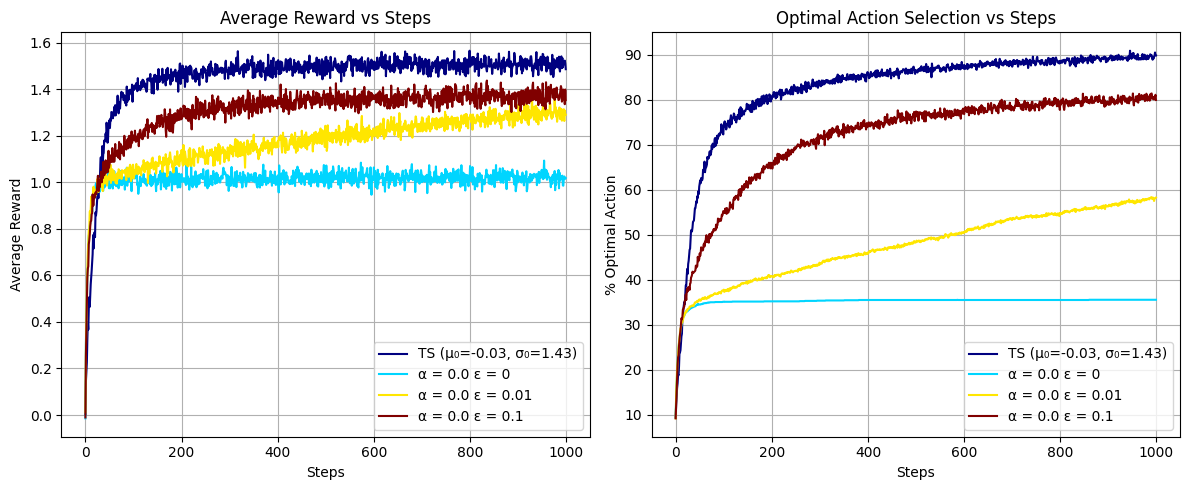

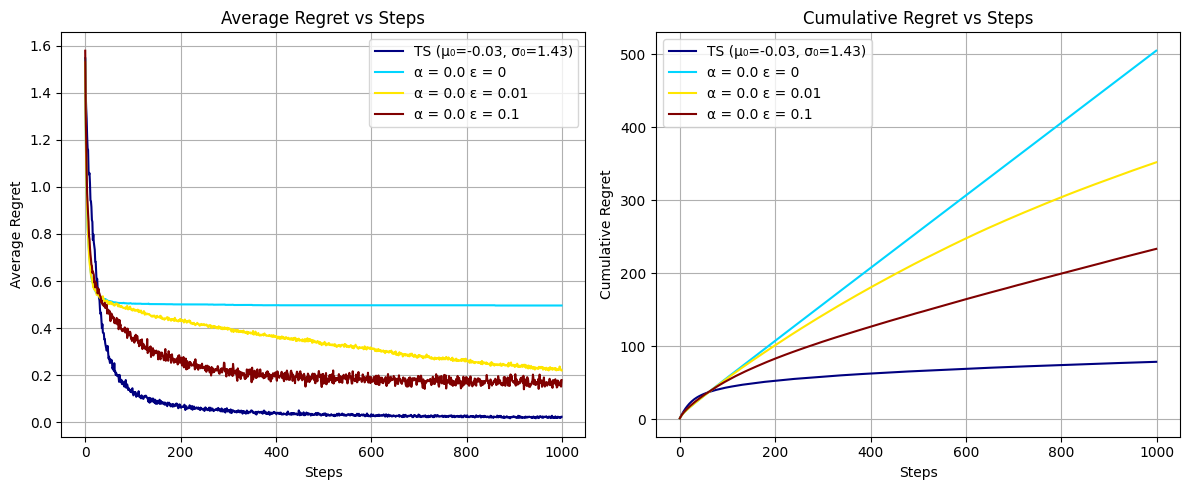

In [ ]:
# Figura 2.2 da página 29 do Sutton Barto incluindo Thompson Sampling e estimativa inicial a priori
env = StationaryKBanditEnv()
alpha = 0.0
epsilon_values = [0, 0.01, 0.1]
num_runs = 2000
num_steps = 1000
mu, sigma = estimate_prior_parameters(env)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)
agents = [agenteTSOtimizado] + [AgentAlpha(env, alpha, epsilon) for epsilon in epsilon_values]
eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose = False)
results = eval.run()

In [ ]:
print("({mu_0}, {sigma_0})", mu, sigma)

({mu_0}, {sigma_0}) -0.027075902264001493 1.4264409326229426


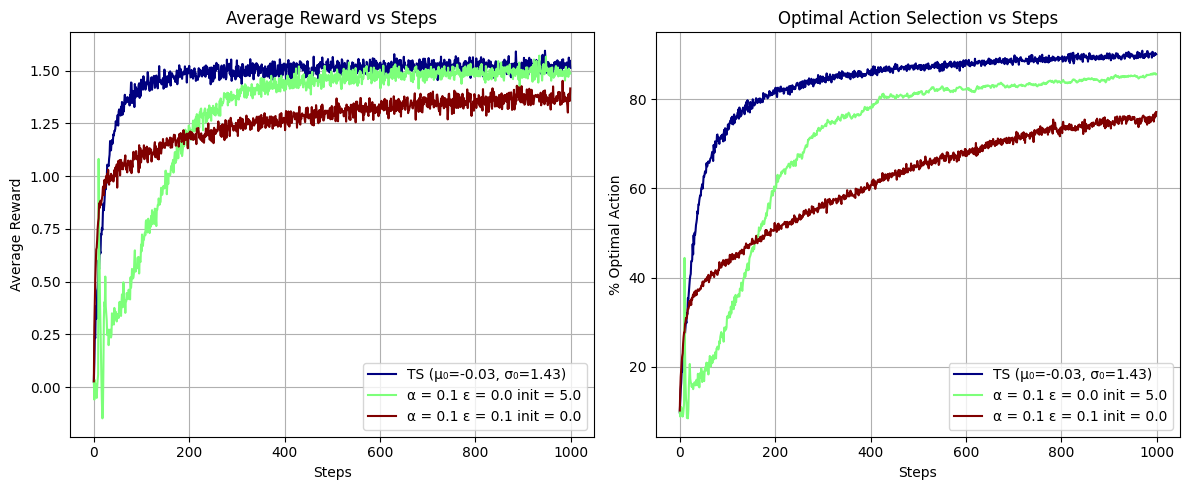

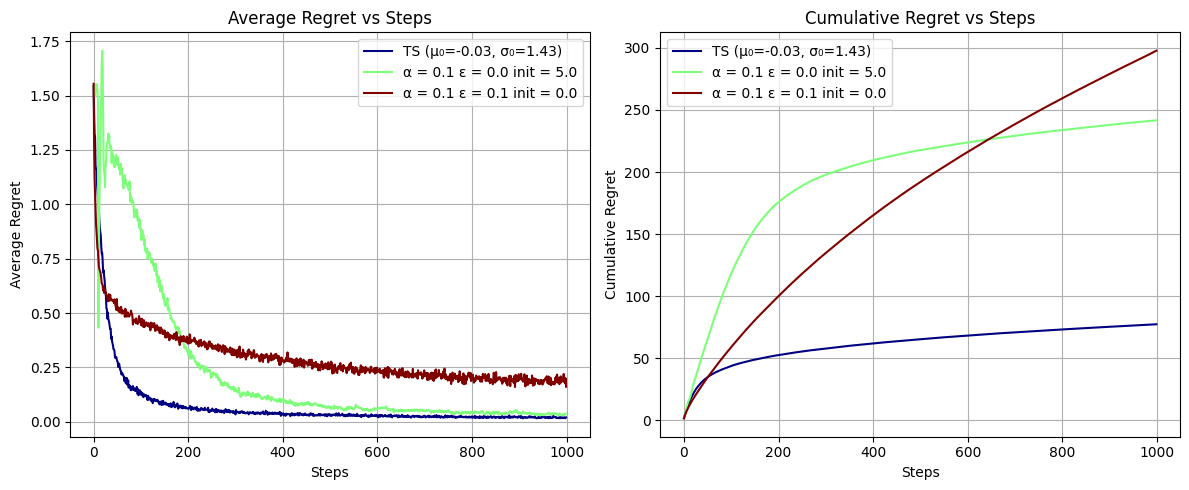

α = 0.1 ε = 0.0 init = 5.0
α = 0.1 ε = 0.1 init = 0.0


In [ ]:
# Caso de Teste da Figura 2.3 da página 34 do Sutton & Barto
# Objetivo: Comparação  de Greedy Puro (ε = 0), inicializaçao otimista (Q0 = 5) e Thompson Sampling
# com ε-Greedy (ε = 0.1) e inicialização zerada (Q0 = 0)
# Agentes: Agentes Alpha e Optimal Init - ε-Greedy (ε = 0.1)
# Ambiente: Estacionário
# Obs: α = 0.1 constante
env = StationaryKBanditEnv()
alpha = 0.1 # Using constant step-size
epsilon_values = [0.0, 0.1]
initial_values = [5.0, 0.0] # Correspondem aos epsilon_values
num_runs = 2000
num_steps = 1000
mu, sigma = estimate_prior_parameters(env)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

agents_optimistic_alpha = []
for epsilon, initial_value in zip(epsilon_values, initial_values):
  agents_optimistic_alpha.append(AgentOptimalInit(env, alpha, epsilon, initial_value))

agents = [agenteTSOtimizado] + agents_optimistic_alpha

eval_optimistic_alpha = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose = False)
results_optimistic_alpha = eval_optimistic_alpha.run()

for agent in agents_optimistic_alpha:
  print(agent.get_label())

In [ ]:
print("({mu_0}, {sigma_0})", mu, sigma)

({mu_0}, {sigma_0}) -0.027075902264001493 1.4264409326229426


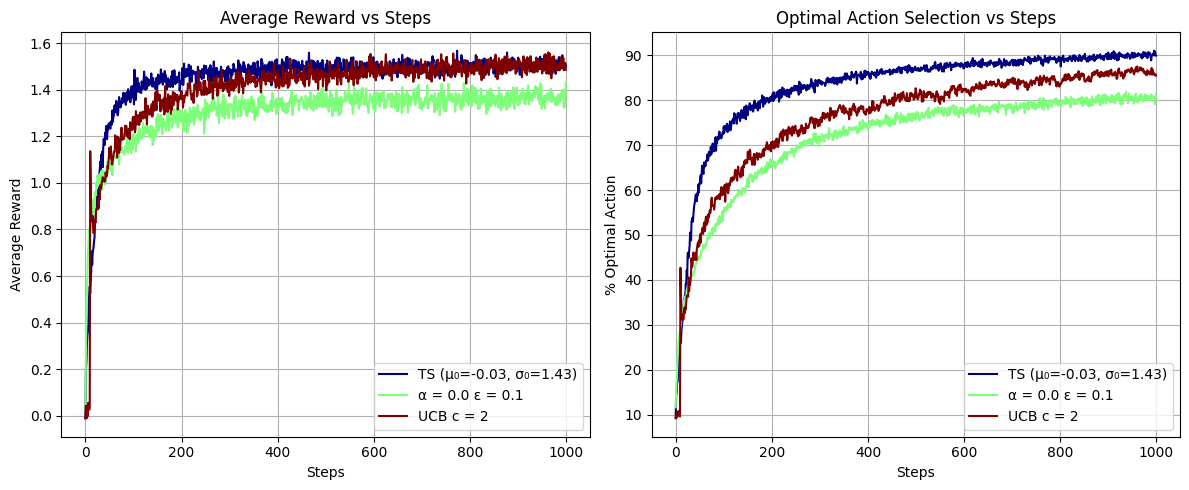

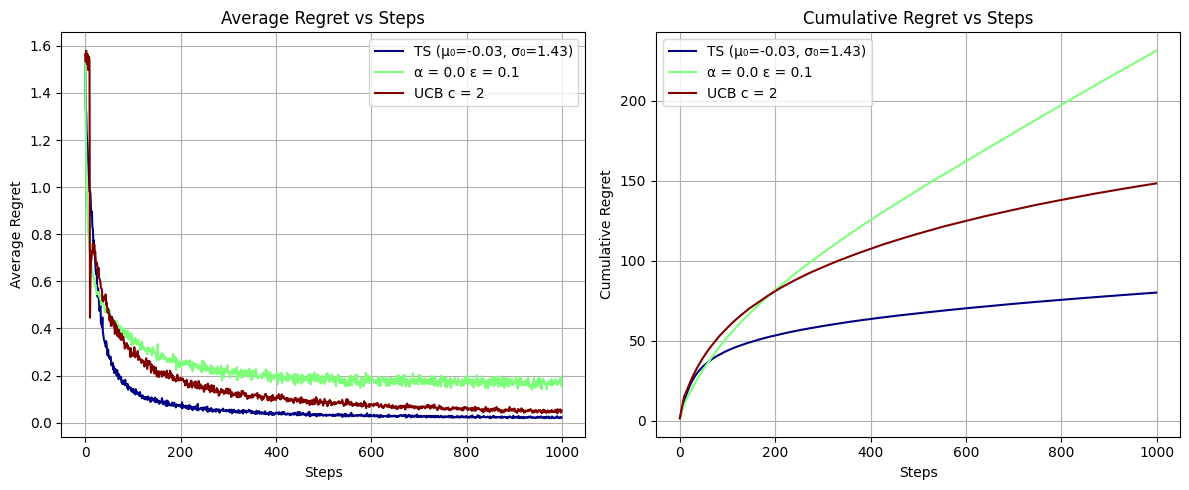

In [ ]:
# Caso de Teste da Figura 2.4 da página 36 do Sutton & Barto
# Objetivo: Comparação  de Agente Alpha - ε-Greedy (ε =  0,1) versus Agente UCB (c = 2)
# Agentes: Agentes Alpha ε-Greedy (ε = 0.1) e UCB (c = 2)
# Ambiente: Estacionário
env = StationaryKBanditEnv()
alpha = 0.0
epsilon = 0.1
c = 2
num_runs = 2000
num_steps = 1000
mu, sigma = estimate_prior_parameters(env)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

agents = [agenteTSOtimizado]+[AgentAlpha(env, alpha, epsilon), AgentUCB(env, c)]
eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose = False)
results = eval.run()

In [ ]:
print("({mu_0}, {sigma_0})", mu, sigma)

({mu_0}, {sigma_0}) -0.027075902264001493 1.4264409326229426


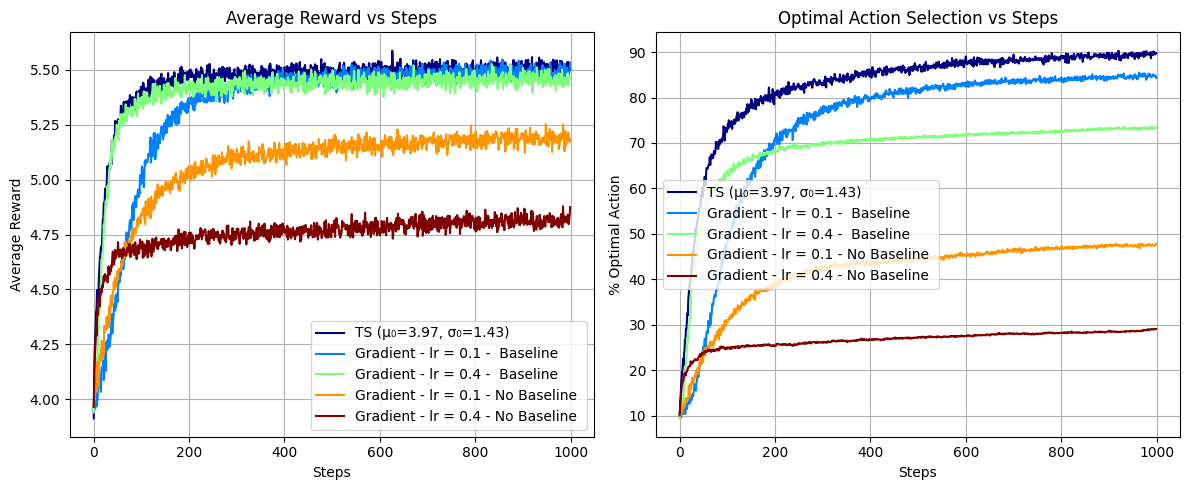

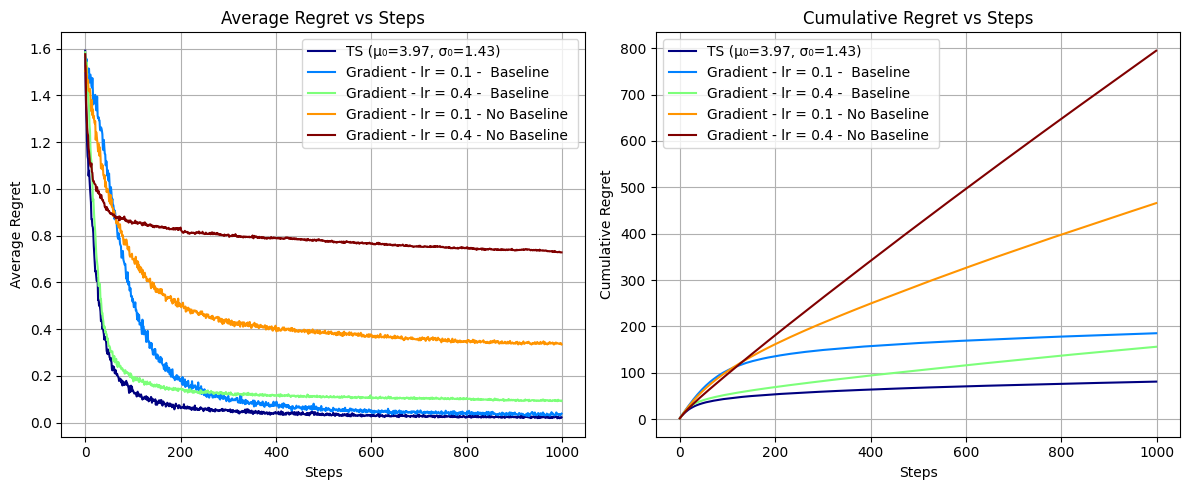

In [ ]:
# Caso de Teste da Figura 2.5 da página 38 do Sutton & Barto
# Objetivo: Comparação  de Agentes Gradiente learning rate - lr (lr = 0.1 e lr = 0.4), com ou sem baseline
# Agentes: Agentes Gradiente
# Ambiente: Estacionário
media = 4
num_runs = 2000
num_steps = 1000

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
env = StationaryKBanditEnv(media_q_true=media)

mu, sigma = estimate_prior_parameters(env)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
# env = StationaryKBanditEnv(media_q_true=media)

alpha_lr_values = [0.1, 0.4, 0.1, 0.4]
baseline_values = [True, True, False, False]

agents_gradient = []
for alpha_lr, baseline in zip(alpha_lr_values, baseline_values):
    # Cada agente tem seu PRÓPRIO ambiente (cópia independente)
    # env = StationaryKBanditEnv(media_q_true=media)
    agents_gradient.append(AgentGradient(env, alpha_lr, baseline))

agents = [agenteTSOtimizado] + agents_gradient

# O evaluator recebe o ambiente de referência (v) para controlar as seeds
eval_gradient = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=False)
results = eval_gradient.run()

In [ ]:
print("({mu_0}, {sigma_0})", mu, sigma)

({mu_0}, {sigma_0}) 3.9729240977359983 1.4264409326229426


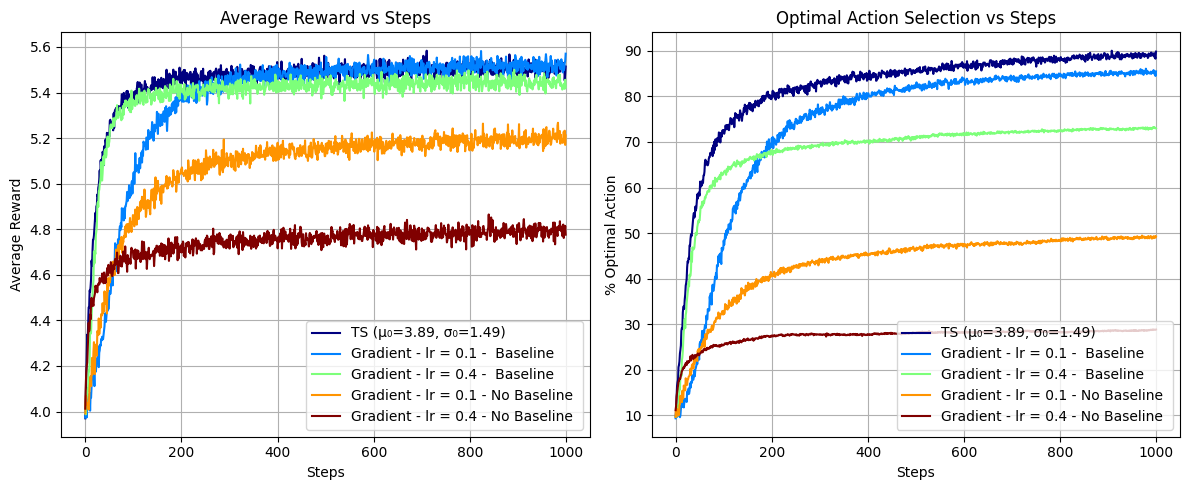

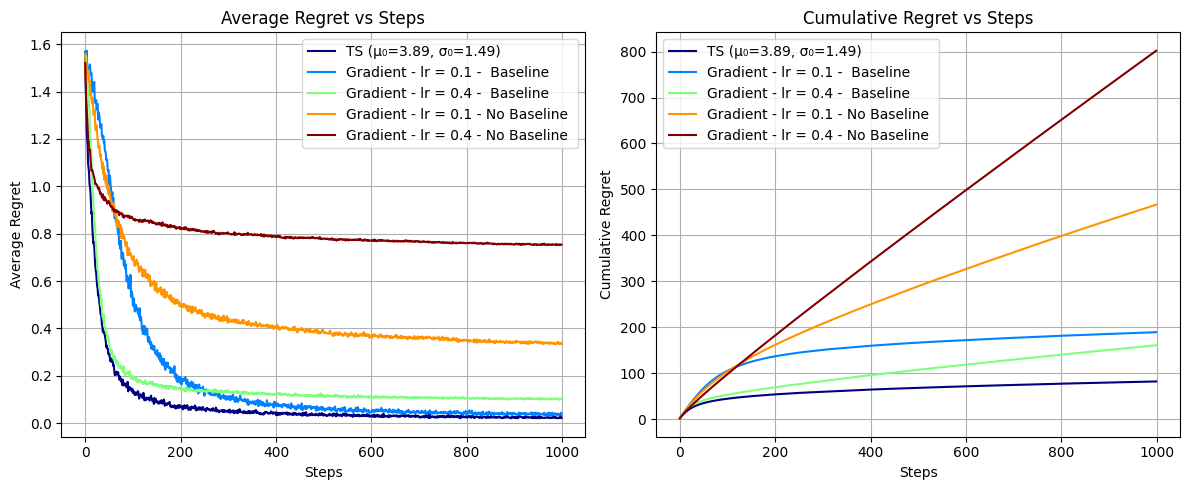

In [ ]:
# Caso de Teste da Figura 2.5 da página 38 do Sutton & Barto
# Objetivo: Comparação  de Agentes Gradiente learning rate - lr (lr = 0.1 e lr = 0.4), com ou sem baseline
# Agentes: Agentes Gradiente
# Ambiente: Estacionário
media = 4
num_runs = 2000
num_steps = 1000

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
env = StationaryKBanditEnv(media_q_true=media)
mu, sigma = estimate_prior_parameters(env, num_samples = 1000)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
#env = StationaryKBanditEnv(media_q_true=media)

alpha_lr_values = [0.1, 0.4, 0.1, 0.4]
baseline_values = [True, True, False, False]

agents_gradient = []
for alpha_lr, baseline in zip(alpha_lr_values, baseline_values):
    # Cada agente tem seu PRÓPRIO ambiente (cópia independente)
    # env = StationaryKBanditEnv(media_q_true=media)
    agents_gradient.append(AgentGradient(env, alpha_lr, baseline))

agents = [agenteTSOtimizado] + agents_gradient

# O evaluator recebe o ambiente de referência (v) para controlar as seeds
eval_gradient = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=False)
results = eval_gradient.run()

In [ ]:
print("({mu_0}, {sigma_0})", mu, sigma)

({mu_0}, {sigma_0}) 3.8882848500647995 1.4886214628934633


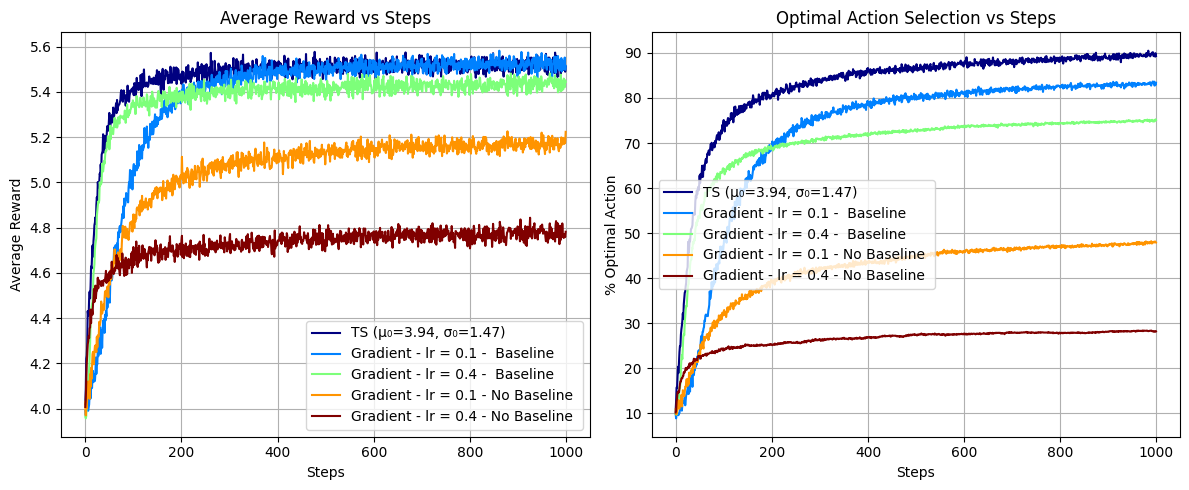

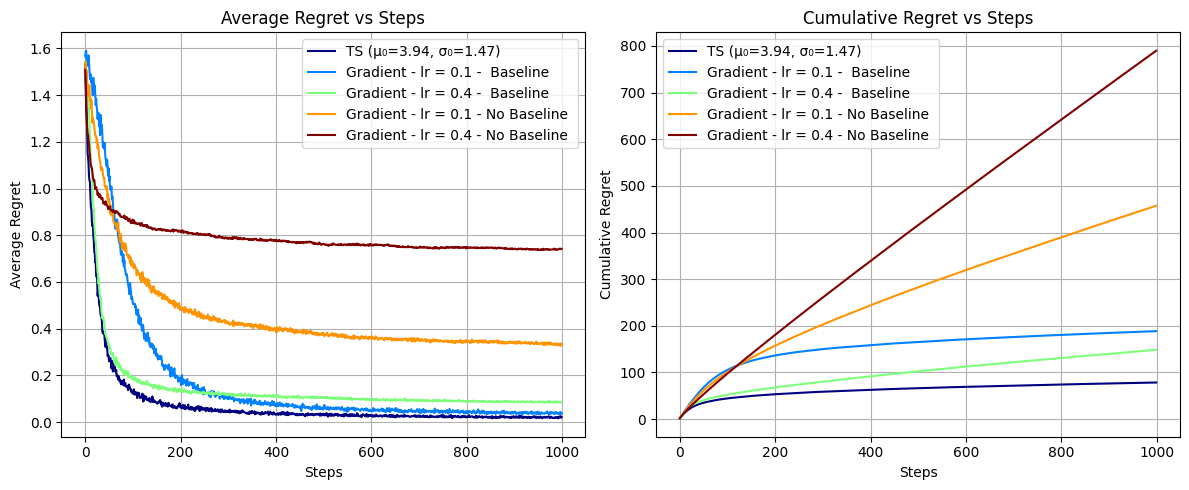

In [ ]:
# Caso de Teste da Figura 2.5 da página 38 do Sutton & Barto
# Objetivo: Comparação  de Agentes Gradiente learning rate - lr (lr = 0.1 e lr = 0.4), com ou sem baseline
# Agentes: Agentes Gradiente
# Ambiente: Estacionário
media = 4
num_runs = 2000
num_steps = 1000

env = StationaryKBanditEnv(media_q_true=media)
mu, sigma = estimate_prior_parameters(env, num_samples = 500)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
# env = StationaryKBanditEnv(media_q_true=media)

alpha_lr_values = [0.1, 0.4, 0.1, 0.4]
baseline_values = [True, True, False, False]

agents_gradient = []
for alpha_lr, baseline in zip(alpha_lr_values, baseline_values):
    # Cada agente tem seu PRÓPRIO ambiente (cópia independente)
    # env = StationaryKBanditEnv(media_q_true=media)
    agents_gradient.append(AgentGradient(env, alpha_lr, baseline))

agents = [agenteTSOtimizado] + agents_gradient

# O evaluator recebe o ambiente de referência (v) para controlar as seeds
eval_gradient = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=False)
results = eval_gradient.run()

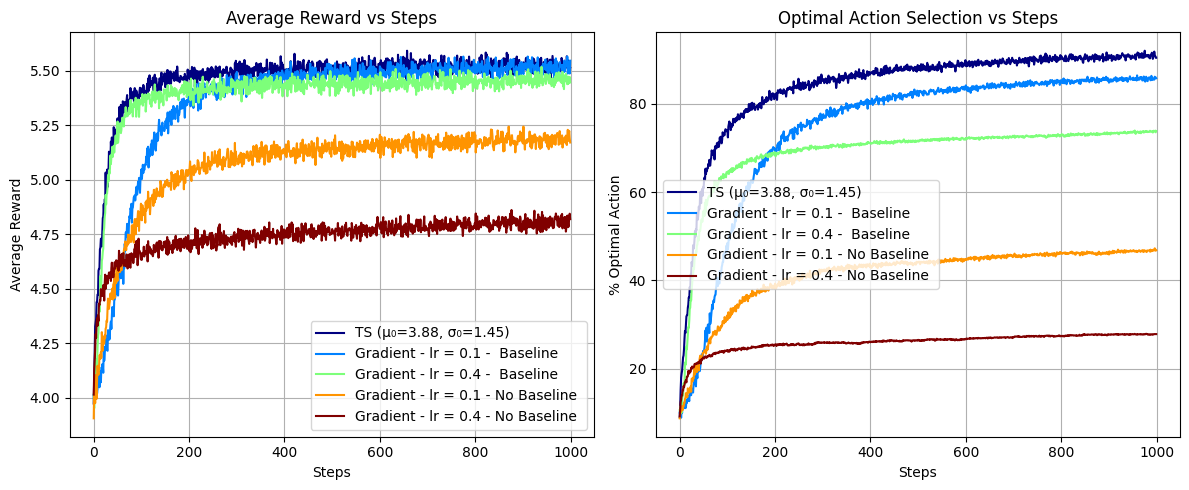

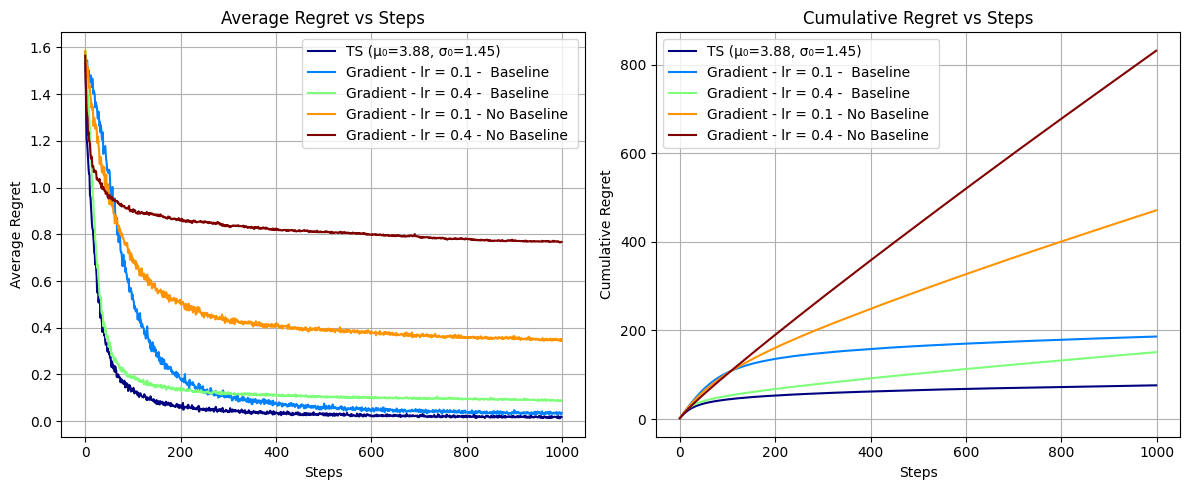

In [ ]:
# Caso de Teste da Figura 2.5 da página 38 do Sutton & Barto
# Objetivo: Comparação  de Agentes Gradiente learning rate - lr (lr = 0.1 e lr = 0.4), com ou sem baseline
# Agentes: Agentes Gradiente
# Ambiente: Estacionário
media = 4
num_runs = 2000
num_steps = 1000
env = StationaryKBanditEnv(media_q_true=media)
mu, sigma = estimate_prior_parameters(env, num_samples = 200)

# env = StationaryKBanditEnv(media_q_true=media)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
# env = StationaryKBanditEnv(media_q_true=media)

alpha_lr_values = [0.1, 0.4, 0.1, 0.4]
baseline_values = [True, True, False, False]

agents_gradient = []
for alpha_lr, baseline in zip(alpha_lr_values, baseline_values):
    # Cada agente tem seu PRÓPRIO ambiente (cópia independente)
    # env = StationaryKBanditEnv(media_q_true=media)
    agents_gradient.append(AgentGradient(env, alpha_lr, baseline))

agents = [agenteTSOtimizado] + agents_gradient

# O evaluator recebe o ambiente de referência (v) para controlar as seeds
eval_gradient = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=False)
results = eval_gradient.run()

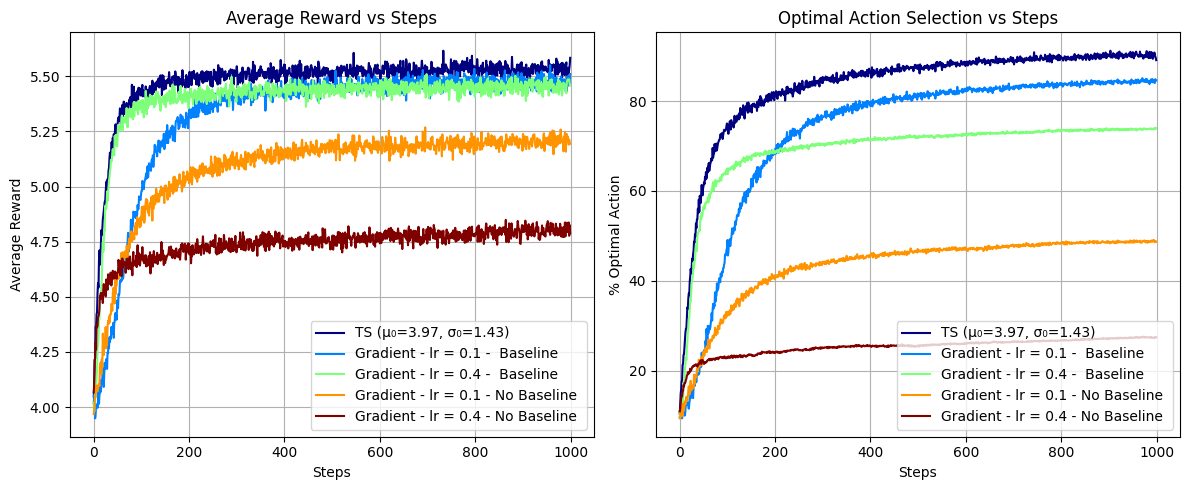

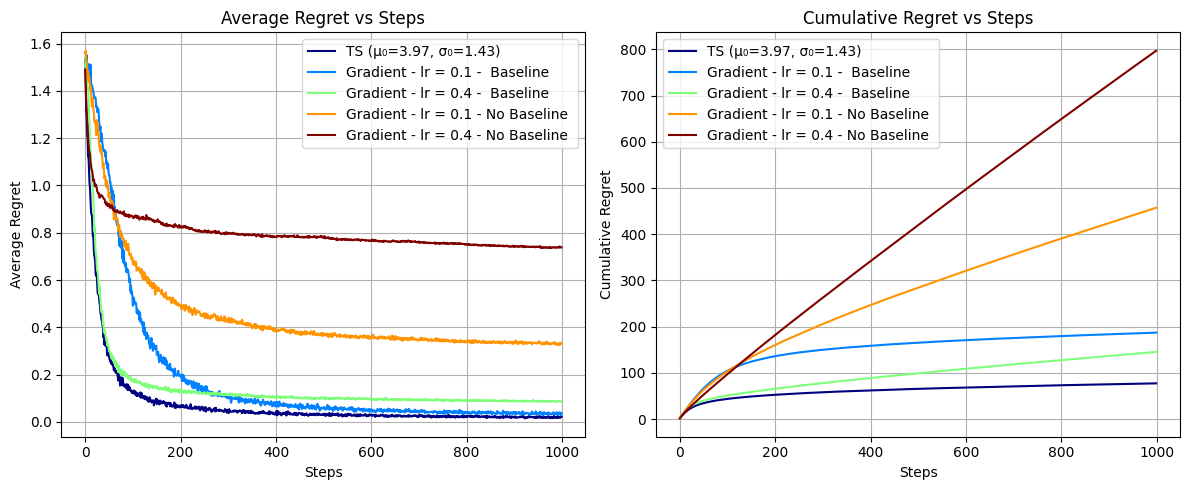

In [ ]:
# Caso de Teste da Figura 2.5 da página 38 do Sutton & Barto
# Objetivo: Comparação  de Agentes Gradiente learning rate - lr (lr = 0.1 e lr = 0.4), com ou sem baseline
# Agentes: Agentes Gradiente
# Ambiente: Estacionário
media = 4
num_runs = 2000
num_steps = 1000
env = StationaryKBanditEnv(media_q_true=media)
mu, sigma = estimate_prior_parameters(env, num_samples = 100)

# env = StationaryKBanditEnv(media_q_true=media)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
# env = StationaryKBanditEnv(media_q_true=media)

alpha_lr_values = [0.1, 0.4, 0.1, 0.4]
baseline_values = [True, True, False, False]

agents_gradient = []
for alpha_lr, baseline in zip(alpha_lr_values, baseline_values):
    # Cada agente tem seu PRÓPRIO ambiente (cópia independente)
    # env = StationaryKBanditEnv(media_q_true=media)
    agents_gradient.append(AgentGradient(env, alpha_lr, baseline))

agents = [agenteTSOtimizado] + agents_gradient

# O evaluator recebe o ambiente de referência (v) para controlar as seeds
eval_gradient = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=False)
results = eval_gradient.run()

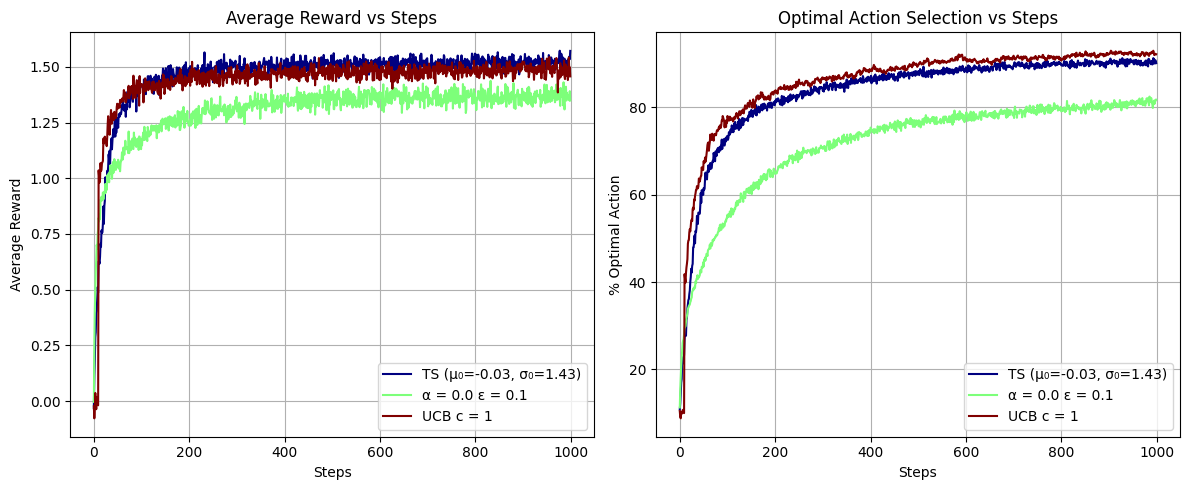

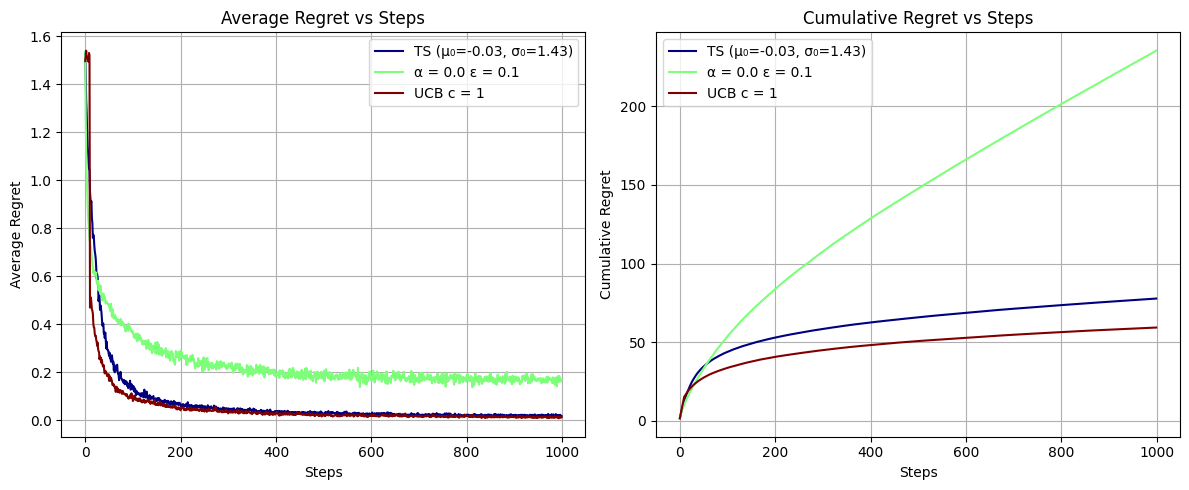

In [ ]:
# Caso de Teste da Figura 2.4 da página 36 do Sutton & Barto com c= 1
# Objetivo: Comparação  de Agente Alpha - ε-Greedy (ε =  0,1) versus Agente UCB (c = 1)
# Agentes: Agentes Alpha ε-Greedy (ε = 0.1) e UCB (c = 1)
# Ambiente: Estacionário
env = StationaryKBanditEnv()
alpha = 0.0
epsilon = 0.1
c = 1
num_runs = 2000
num_steps = 1000
mu, sigma = estimate_prior_parameters(env)
agenteTSOtimizado = AgentTSOtimizado(env, mu_0=mu, sigma_0=sigma)

agents = [agenteTSOtimizado]+[AgentAlpha(env, alpha, epsilon), AgentUCB(env, c)]
eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose = False)
results = eval.run()